# Laboratorio 4: Construcción de Portafolios — Markowitz, Black-Litterman y Risk Parity 

**Curso:** Finanzas Computacionales  
**Programa:** Magíster en Business Analytics (UAI)  
**Autor:** Francisco Andrés Cisternas García  
**Fecha:** 12 de noviembre de 2026


In [1]:
# --- Setup ---
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # quantstats pide Arial; si no está, usa otra

# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
import scipy.optimize as sco
import quantstats as qs
import riskfolio as rp

# Paleta de colores y figuras
NAVY, BLUE, ACCENT, GREY = "#1F3864", "#2E5496", "#C55A11", "#8A8F98"
GREEN, RED, GOLDC = "#2E7D57", "#B23A3A", "#B8860B"
COLS = [NAVY, BLUE, ACCENT, GREEN, GOLDC, GREY]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlecolor": NAVY, "font.size": 11})

# Parámetros financieros fundamentales
RF = 0.02          # tasa libre de riesgo anual
ANN = 252          # días hábiles por año
rfd = RF / ANN     # tasa libre de riesgo diaria (Riskfolio trabaja con datos diarios)
print("Entorno listo. Riskfolio-Lib", rp.__version__, "| quantstats", qs.__version__)

Entorno listo. Riskfolio-Lib 7.4.1 | quantstats 0.0.86


## Datos, respaldo CSV, benchmark y momentos anuales.

In [2]:
# 4 activos de renta variable (2 defensivos, 2 crecimiento), 1 activo de bonos y 1 de commodities
TICKERS = {"KO": "KO", "JNJ": "JNJ", "GOOGL": "GOOGL", "NVDA": "NVDA", "BND": "BND", "USO": "USO"}
# Benchmark: 60% Renta Variable (15% en cada acción), 30% Renta Fija (BND), 10% Materias Primas (USO)
BENCHMARK = {"KO": 0.15, "JNJ": 0.15, "GOOGL": 0.15, "NVDA": 0.15, "BND": 0.30, "USO": 0.10}
# Datos
INICIO = "2018-01-01"
FIN = "2026-11-11"      # fecha de corte fija (exclusiva): el último dato es 2026-11-10
RESPALDO = "mis_precios_taller4.csv"

def get_prices(tickers, backup=RESPALDO, start=INICIO, end=FIN):
    import contextlib, io, logging
    try:
        import yfinance as yf
        logging.getLogger("yfinance").setLevel(logging.CRITICAL)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            data = yf.download(list(tickers.keys()), start=start, end=end, auto_adjust=True, progress=False)
        px = data["Close"].dropna()
        if px.shape[0] < 500:
            raise RuntimeError("datos insuficientes")
        
        # Guardar en CSV de respaldo
        px_final = px.rename(columns=tickers)[list(tickers.values())]
        px_final.to_csv(backup)
        print(f"Precios reales descargados de yfinance y respaldados en: {backup}")
        return px_final[px_final.index < end]
    except Exception as e:
        print(f"No se pudo descargar ({e}). Usando respaldo local: {backup}")
        return pd.read_csv(backup, index_col=0, parse_dates=True).loc[lambda d: d.index < end]

# Retornos y momentos historicos
precios = get_prices(TICKERS, backup=RESPALDO, start=INICIO, end=FIN)
retornos = precios.pct_change().dropna()
ASSETS = list(retornos.columns)
n = len(ASSETS)
R = retornos.values
print(f"{len(retornos)} días, desde {retornos.index[0]:%Y-%m-%d} hasta {retornos.index[-1]:%Y-%m-%d}")
print("\n----- Retornos -----")
display(retornos.head())

avg_returns = retornos.mean() * ANN        # retorno esperado anual (promedio histórico)
cov_mat = retornos.cov() * ANN             # covarianza anual
vol = np.sqrt(np.diag(cov_mat))
mu, cov = avg_returns.values, cov_mat.values
resumen = pd.DataFrame({"Retorno esp.": mu, "Volatilidad": vol, "Sharpe indiv.": (mu - RF) / vol}, index=ASSETS)
print("\n----- Retornos, Volatilidad y Sharpe indvidual -----")
resumen.style.format({"Retorno esp.": "{:.1%}", "Volatilidad": "{:.1%}", "Sharpe indiv.": "{:.2f}"})

Precios reales descargados de yfinance y respaldados en: mis_precios_taller4.csv
2226 días, desde 2018-01-03 hasta 2026-11-10

----- Retornos -----


Ticker,KO,JNJ,GOOGL,NVDA,BND,USO
Date,,,,,,
2018-01-03,-0.002196,0.009552,0.017061,0.065814,0.000861,0.022370
2018-01-04,0.014085,-0.000071,0.003884,0.005271,-0.000491,0.002431
2018-01-05,-0.000217,0.008253,0.013260,0.008474,-0.001352,-0.004850
2018-01-08,-0.001519,0.001271,0.003531,0.030640,0.000123,0.005686
2018-01-09,0.005000,0.015857,-0.001274,-0.000270,-0.002953,0.015347



----- Retornos, Volatilidad y Sharpe indvidual -----


,Retorno esp.,Volatilidad,Sharpe indiv.
KO,13.5%,19.3%,0.59
JNJ,12.6%,19.8%,0.54
GOOGL,24.0%,31.3%,0.70
NVDA,52.7%,50.3%,1.01
BND,1.7%,5.8%,-0.05
USO,12.9%,41.0%,0.27


## Correlaciones y pruebas de Jarque-Bera/asimetría/curtosis.

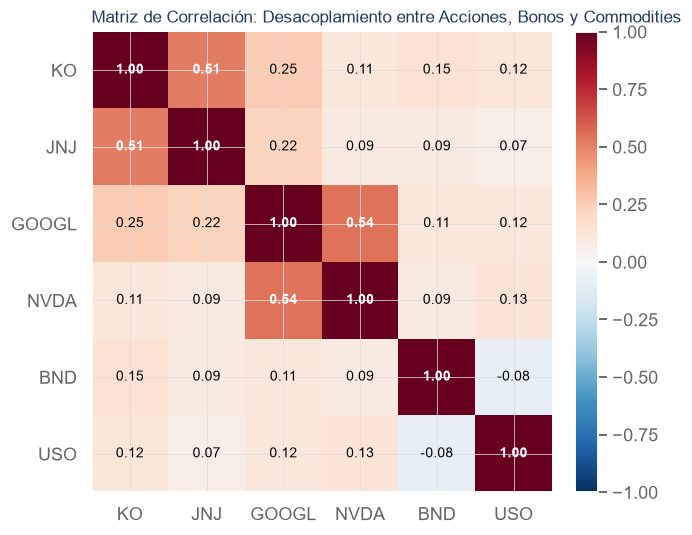

In [3]:
# Matriz de correlación
corr = retornos.corr()

fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(ASSETS)
ax.set_yticks(range(n)); ax.set_yticklabels(ASSETS)
for i in range(n):
    for j in range(n):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(val) > 0.45 else "black", weight="bold" if abs(val) > 0.5 else "normal")
ax.set_title("Matriz de Correlación: Desacoplamiento entre Acciones, Bonos y Commodities", loc="left", fontsize=11)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Diagnóstico de correlaciones:
Tenemos 3 bloques de activos, los defensivos compuestos por KO y JNJ; los de crecimiento por NVDA y GOOGL; y, por último, los desacoplados por los ETF BND y USO. Los defensivos son acciones de consumo masivo y salud; los de crecimiento son tecnologías que van en crecimiento; los últimos son dos ETF que funcionan como un escudo de amortiguación ante cambios bruscos en los mercados financieros.

- Los activos defensivos presentan una correlación positiva moderada (0,51).
- Los de crecimiento presentan una correlación moderada (0,54).
- Los desacoplados presentan correlaciones bajas o nulas con respecto a las acciones (entre -0,08 a 0,15).

,Asimetría (Diaria),Curtosis Exceso (Diaria),JB Estadístico,JB p-valor,Curtosis Exceso (Mensual)
KO,-0.505,8.14,"6,236.4",0.0000e+00,0.88
JNJ,-0.232,7.94,"5,861.4",0.0000e+00,-0.22
GOOGL,-0.064,4.36,"1,760.6",0.0000e+00,1.08
NVDA,0.136,4.82,"2,161.3",0.0000e+00,-0.14
BND,-0.892,32.64,"99,118.8",0.0000e+00,0.33
USO,-0.956,12.78,"15,486.1",0.0000e+00,5.97
Portafolio 1/N,-0.704,9.42,"8,415.2",0.0000e+00,1.39


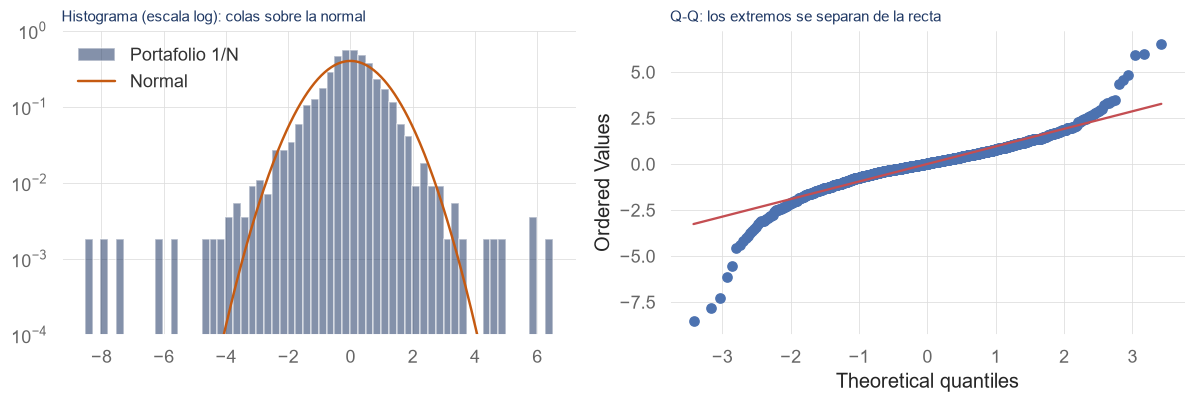

In [4]:
# Normalidad

# Portafolio equiponderado
w_eq = np.ones(n) / n
r_eq = pd.Series(R @ w_eq, index=retornos.index, name="Portafolio 1/N")
rets_m = (1 + retornos).resample("ME").prod() - 1
r_eq_m = (1 + r_eq).resample("ME").prod() - 1

# Medición de las estadisticas de normalidad
def normalidad(serie_d, serie_m):
    jb_stat, jb_pval = stats.jarque_bera(serie_d)
    return {
        "Asimetría (Diaria)": stats.skew(serie_d),
        "Curtosis Exceso (Diaria)": stats.kurtosis(serie_d),
        "JB Estadístico": jb_stat,
        "JB p-valor": jb_pval,
        "Curtosis Exceso (Mensual)": stats.kurtosis(serie_m)
    }

tab_norm = pd.DataFrame({a: normalidad(retornos[a], rets_m[a]) for a in ASSETS} |
                        {"Portafolio 1/N": normalidad(r_eq, r_eq_m)}).T

display(tab_norm.style.format({
    "Asimetría (Diaria)": "{:.3f}",
    "Curtosis Exceso (Diaria)": "{:.2f}",
    "JB Estadístico": "{:,.1f}",
    "JB p-valor": "{:.4e}",
    "Curtosis Exceso (Mensual)": "{:.2f}"
}))

# Estandarización
z = (r_eq - r_eq.mean()) / r_eq.std()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
# Colas pesadas (Histograma en escala logaritmica)
axes[0].hist(z, bins=60, density=True, color=NAVY, alpha=0.55, label="Portafolio 1/N")
xs = np.linspace(-5.5, 5.5, 300)
axes[0].plot(xs, stats.norm.pdf(xs), color=ACCENT, lw=1.6, label="Normal")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-4, 1); axes[0].legend(frameon=False)
axes[0].set_title("Histograma (escala log): colas sobre la normal", loc="left", fontsize=10)

# Grafico Q-Q Normal
stats.probplot(z, dist="norm", plot=axes[1])
axes[1].set_title("")  # Elimina el título por defecto "Probability Plot"
axes[1].set_title("Q-Q: los extremos se separan de la recta", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## Diagnóstico de normalidad:
Todos los retornos presentan una asimetría negativa menos NVDA, aún así la normalidad debería ser una asimetría exacta de 0. Todos los activos presentan un exceso de curtosis alto (lo normal sería 0) presentando colas pesadas, por lo que los eventos extremos ocurren con mayor frecuencia (observar las colas que salen fuera de la curva normal en el histograma). Observando el gráfico Q-Q podemos ver como si fuera una S, notando así las colas pesadas y falta de normalidad. Con el test de Jarque-Bera donde la hipótesis nula es normalidad, podemos ver cómo todos los p-valores son < 0,05 por lo que se rechaza la hipótesis nula (falta de normalidad).

## Frontera de Markowitz desde (0,0), LMC, Mínima Varianza y Máximo Sharpe.

#### Restricciones:
- Todo el capital invertido
- Solo posiciones largas 

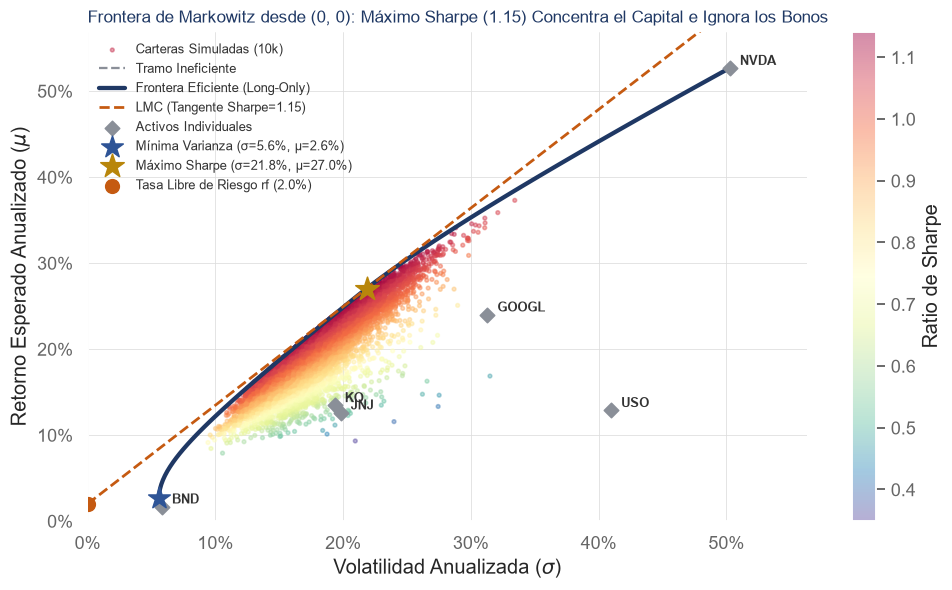

,Mínima Varianza,Máximo Sharpe
KO,1.11%,32.03%
JNJ,4.63%,26.01%
GOOGL,0.06%,3.72%
NVDA,0.00%,34.21%
BND,91.53%,0.00%
USO,2.67%,4.03%


,Mínima Varianza,Máximo Sharpe
--- Retorno Esperado (μ) ---,2.64%,27.03%
--- Volatilidad (σ) ---,5.57%,21.84%
--- Ratio de Sharpe ---,0.11,1.15


In [5]:
# Retorno esperado del portafolio
def get_portf_rtn(w, avg_rtns):
    return np.sum(avg_rtns * w)

# Volatilidad del portafolio
def get_portf_vol(w, avg_rtns, cov_mat):
    return np.sqrt(np.dot(w.T, np.dot(cov_mat, w)))

# Restricciones
capital100 = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
w0 = n * [1.0 / n]
longterm = tuple((0, 1) for _ in range(n))

# Minima varianza 
w_mv = sco.minimize(get_portf_vol, w0, args=(mu, cov), bounds=longterm, constraints=capital100,
                    options={"ftol": 1e-12, "maxiter": 500}).x
r_mv, v_mv = get_portf_rtn(w_mv, mu), get_portf_vol(w_mv, mu, cov)

# Maxima Sharpe
w_ms = sco.minimize(lambda w: -(get_portf_rtn(w, mu) - RF) / get_portf_vol(w, mu, cov), w0,
                    bounds=longterm, constraints=capital100, options={"ftol": 1e-12, "maxiter": 500}).x
r_ms, v_ms = get_portf_rtn(w_ms, mu), get_portf_vol(w_ms, mu, cov)
s_ms = (r_ms - RF) / v_ms

# Construcción de la frontera eficiente
def get_efficient_frontier(avg_rtns, cov_mat, rtns_range):
    efficient_portfolios = []
    n_assets = len(avg_rtns)
    args = (avg_rtns, cov_mat)
    bounds = tuple((0, 1) for _ in range(n_assets))
    initial_guess = n_assets * [1.0 / n_assets]
    for ret in rtns_range:
        constr = ({"type": "eq", "fun": lambda x, ret=ret: get_portf_rtn(x, avg_rtns) - ret},
                  {"type": "eq", "fun": lambda x: np.sum(x) - 1})
        ef_portf = sco.minimize(get_portf_vol, initial_guess, args=args, method="SLSQP",
                                constraints=constr, bounds=bounds)
        efficient_portfolios.append(ef_portf)
    return efficient_portfolios

rtns_range = np.linspace(avg_returns.min(), avg_returns.max(), 100)
efficient_portfolios = get_efficient_frontier(avg_returns.values, cov_mat.values, rtns_range)
vols_range = np.array([x["fun"] for x in efficient_portfolios])

# 4. Nube de 10.000 carteras aleatorias
np.random.seed(42)
rand_w = np.random.random(size=(10000, n))
rand_w /= np.sum(rand_w, axis=1)[:, np.newaxis]
rand_r = rand_w @ mu
rand_v = np.sqrt(np.einsum("ij,jk,ik->i", rand_w, cov, rand_w))
rand_s = (rand_r - RF) / rand_v

# 5. Gráfico de la Frontera Eficiente trazada desde (0, 0) con Línea de Mercado de Capitales (LMC)
ef_mask = (rtns_range >= r_mv - 1e-6) & (~np.isnan(vols_range))
xmax = max(vol.max() * 1.12, v_ms * 1.8)
ymax = max(mu.max() * 1.08, r_ms * 1.15)
xs_lmc = np.linspace(0, xmax, 100)
lmc = RF + s_ms * xs_lmc

fig, ax = plt.subplots(figsize=(9.2, 5.5))
sc = ax.scatter(rand_v, rand_r, c=rand_s, cmap="Spectral_r", s=6, alpha=0.45, label="Carteras Simuladas (10k)")
ax.plot(vols_range[~ef_mask], rtns_range[~ef_mask], color=GREY, ls="--", lw=1.5, label="Tramo Ineficiente")
ax.plot(vols_range[ef_mask], rtns_range[ef_mask], color=NAVY, lw=2.8, label="Frontera Eficiente (Long-Only)")
ax.plot(xs_lmc, lmc, color=ACCENT, ls="--", lw=1.8, label=f"LMC (Tangente Sharpe={s_ms:.2f})")

# Activos individuales
ax.scatter(vol, mu, color=GREY, marker="D", s=45, zorder=5, label="Activos Individuales")
for i, a in enumerate(ASSETS):
    ax.annotate(f" {a}", (vol[i], mu[i]), xytext=(4, 2), textcoords="offset points", fontsize=8.5, weight="bold")

# Puntos clave
ax.scatter(v_mv, r_mv, marker="*", s=220, color=BLUE, zorder=6, label=f"Mínima Varianza (σ={v_mv:.1%}, μ={r_mv:.1%})")
ax.scatter(v_ms, r_ms, marker="*", s=260, color=GOLDC, zorder=6, label=f"Máximo Sharpe (σ={v_ms:.1%}, μ={r_ms:.1%})")
ax.scatter(0, RF, marker="o", s=80, color=ACCENT, zorder=6, label=f"Tasa Libre de Riesgo rf ({RF:.1%})")

# Ajuste estricto desde el origen (0, 0)
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Volatilidad Anualizada ($\sigma$)")
ax.set_ylabel("Retorno Esperado Anualizado ($\mu$)")
ax.set_title("Frontera de Markowitz desde (0, 0): Máximo Sharpe (1.15) Concentra el Capital e Ignora los Bonos", loc="left", fontsize=11)
cb = fig.colorbar(sc, label="Ratio de Sharpe")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.show()

# Calcular el Sharpe de Mínima Varianza
s_mv = (r_mv - RF) / v_mv

# Tabla comparativa de pesos: Mínima Varianza vs Máximo Sharpe
tabla_markowitz = pd.DataFrame({
    "Mínima Varianza": w_mv,
    "Máximo Sharpe": w_ms
}, index=ASSETS)

# Agregamos las métricas clave al final de la tabla
resumen_metricas = pd.DataFrame({
    "Mínima Varianza": [r_mv, v_mv, s_mv],
    "Máximo Sharpe":   [r_ms, v_ms, s_ms]
}, index=["--- Retorno Esperado (μ) ---", "--- Volatilidad (σ) ---", "--- Ratio de Sharpe ---"])

# Mostrar tabla estilizada con porcentajes
display(tabla_markowitz.style.format("{:.2%}"))
display(resumen_metricas.style.format({
    "Mínima Varianza": lambda x: f"{x:.2f}" if "Sharpe" in resumen_metricas.index[resumen_metricas["Mínima Varianza"] == x][0] else f"{x:.2%}",
    "Máximo Sharpe":   lambda x: f"{x:.2f}" if "Sharpe" in resumen_metricas.index[resumen_metricas["Máximo Sharpe"] == x][0] else f"{x:.2%}"
}))

## Interpretación de Markowitz
Se presentan dos restricciones:
- La inversión total del presupuesto y sin apalancamiento.
- Solo posiciones largas, ya que aumenta el riesgo y necesitamos liquidez.

1. Cartera de Mínima Varianza: Se asigna un 91,53% del capital total a la renta fija (BND) complementando con activos defensivos (KO: 1,11%, USO: 2,67%, JNJ: 4,63%) dejando afuera a los activos de mayor volatilidad y retornos. Consigue una volatilidad baja de 5,57% logrando el objetivo de minimizar el riesgo. Sin embargo, el resultado de ello es el sacrificio del retorno esperado (2,64% anual) con un ratio de Sharpe de 0,11.

2. Cartera de Máximo Sharpe: Se asigna el 92,25% (92,2% al redondear a un decimal) del capital en solamente 3 activos (KO, JNJ y NVDA) donde solamente 1 de ellos presenta una volatilidad de 50,3% (NVDA), con un porcentaje pequeño en GOOGL y USO e ignorando por completo a los bonos (BND). Ofrece un retorno esperado de 27,03% pero con una volatilidad del 21,84% y su ratio de Sharpe es de 1,15.

En ambas carteras se presenta una alta concentración del capital. En Máximo Sharpe se le asigna prácticamente un tercio del capital a un activo sumamente volátil. El portafolio que maximiza Sharpe sobrepondera a NVDA por sus retornos históricos de los últimos años; si las condiciones macroeconómicas relacionadas a la IA cambian, se podría enfrentar a una inestabilidad enorme.

## Black-Litterman con 𝛿, 𝑤𝑚𝑘t y 2 visiones explícitas.

In [6]:
# 1. Pesos individuales dentro del índice Dow Jones (^DJI) de Slickcharts
w_DJI = {"NVDA": 0.0192, "GOOGL": 0.0327, "KO": 0.0110, "JNJ": 0.0320}

# 2. Normalización de las acciones para que ocupen el 60% del portafolio
suma_dji = sum(w_DJI.values())  # suma = 0.0949
w_acciones = {accion: (peso / suma_dji) * 0.60 for accion, peso in w_DJI.items()}

# 3. Construcción del vector de mercado 60 / 30 / 10 completo
w_mkt_dict = {
    **w_acciones,     # 60% repartido según el Dow Jones
    "BND": 0.30,      # 30% Renta Fija
    "USO": 0.10       # 10% Materias Primas
}

# Convertir a Series indexada en el orden exacto de tus activos
w_mkt = pd.Series(w_mkt_dict)[ASSETS]

# 4. Verificación y visualización
print("=== Ponderaciones de Equilibrio de Mercado (w_mkt) ===")
display(w_mkt.to_frame("Ponderación w_mkt").style.format("{:.2%}"))
print(f"Suma total del portafolio: {w_mkt.sum():.2%}")

=== Ponderaciones de Equilibrio de Mercado (w_mkt) ===


,Ponderación w_mkt
KO,6.95%
JNJ,20.23%
GOOGL,20.67%
NVDA,12.14%
BND,30.00%
USO,10.00%


Suma total del portafolio: 100.00%


Para definir el vector de equilibrio w<sub>mkt</sub> de Black-Litterman, se aplicó una estructura institucional de referencia de 60% renta variable, 30% renta fija y 10% materias primas. Para evitar la arbitrariedad de ponderar las acciones en partes iguales, se decidió ponderar según el peso relativo dentro del índice Dow Jones Industrial Average (^DJI), junto con un coeficiente de aversión al riesgo $\delta = 2,5$ (estándar institucional de mercado).

#### Formulación de las visiones (P, Q):
- NVDA y GOOGL le ganarán a KO y JNJ por 6 puntos porcentuales anualizados ya que el sector tecnológico se ve impulsado por una mayor inversión en IA. # Relativa
- El retorno esperado de BND ofrecerá un exceso de 1% anual sobre la tasa libre de riesgo ($r_f = 2\%$). A la fecha de corte, la moderación inflacionaria estadounidense proyecta menores presiones de tasas e impulsa el desempeño de los bonos. # Absoluta

Matriz de Selección de Visiones P:


,KO,JNJ,GOOGL,NVDA,BND,USO
0,-0.5,-0.5,0.5,0.5,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0


Vector de Retornos de las Visiones Q:


,Retorno Visión
0,0.06
1,0.01


,Peso Mercado,μ Histórico,Π Equilibrio,μ BL (Fórmula),μ BL (Riskfolio),w Markowitz,w Black-Litterman
KO,7.0%,13.47%,5.13%,5.39%,5.39%,32.0%,6.5%
JNJ,20.2%,12.62%,5.52%,5.74%,5.74%,26.0%,16.5%
GOOGL,20.7%,24.01%,11.14%,10.70%,10.70%,3.7%,14.5%
NVDA,12.1%,52.68%,15.56%,14.53%,14.53%,34.2%,8.0%
BND,30.0%,1.69%,2.47%,2.73%,2.73%,0.0%,47.0%
USO,10.0%,12.90%,8.05%,7.80%,7.80%,4.0%,7.6%


Diferencia máxima en mu_BL (Fórmula vs Riskfolio): 4.16e-17


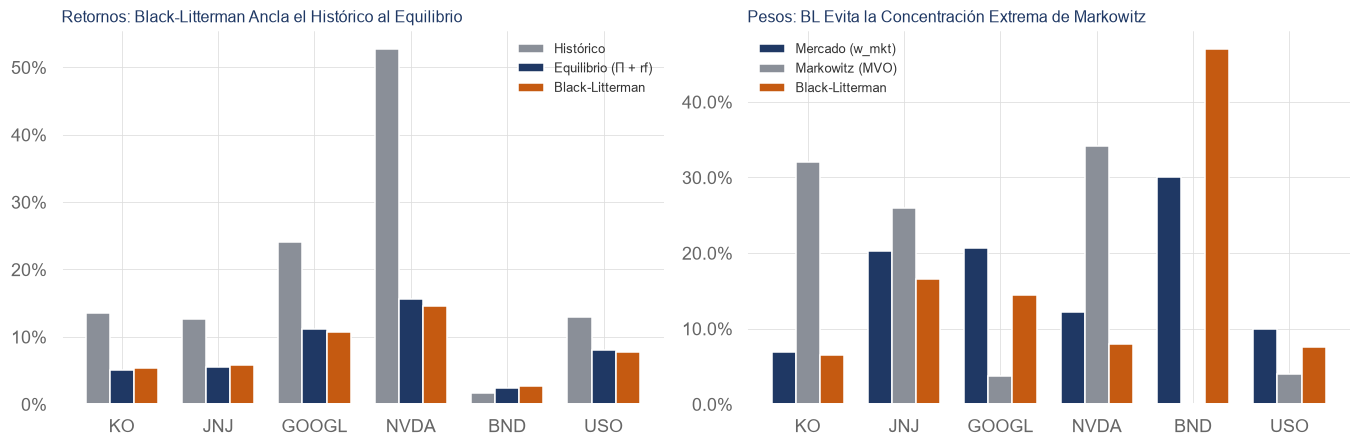

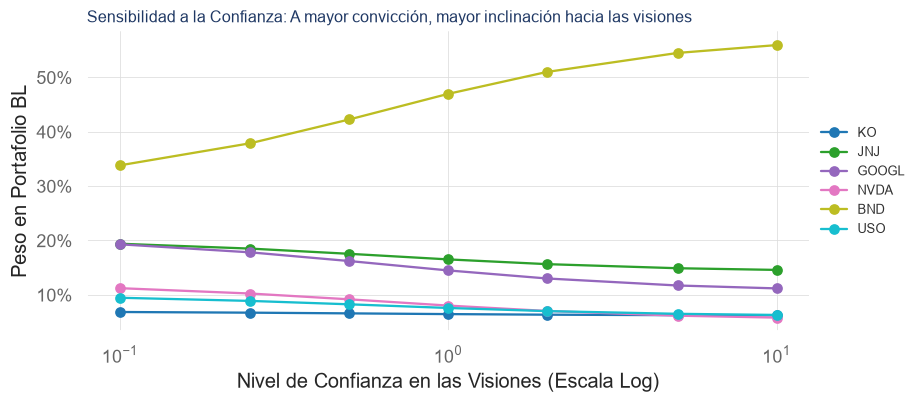

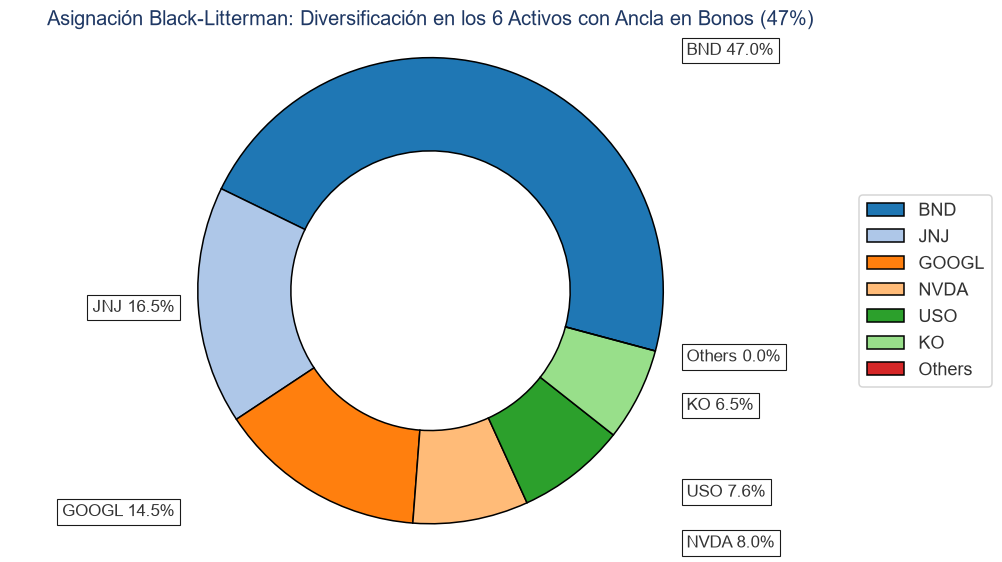

In [7]:
# Para el coeficiente de de aversión al riesgo se utilzó un delta de 2,5.
DELTA = 2.5

# Formulación de las visiones (P, Q):
vistas = [
    ({"NVDA": 0.5, "GOOGL": 0.5, "KO": -0.5, "JNJ": -0.5}, 0.06), # V1: Relativa
    ({"BND": 1.0}, 0.01)                                          # V2: Absoluta en exceso de rf
]

P = pd.DataFrame([{a: c for a, c in v.items()} for v, _ in vistas], columns=ASSETS).fillna(0.0)
Q = pd.DataFrame([q for _, q in vistas], columns=["Retorno Visión"])


print("Matriz de Selección de Visiones P:")
display(P)
print("Vector de Retornos de las Visiones Q:")
display(Q)

# 3. Implementación Analítica por Fórmula Matricial
def black_litterman(S, w_mkt, P, Q, delta=DELTA, tau=0.05, confianza=1.0):
    """Calcula retornos de equilibrio Pi y media posterior de Black-Litterman mu_BL."""
    P = np.asarray(P, float)
    Q = np.asarray(Q, float).ravel()
    w_arr = np.asarray(w_mkt, float)
    
    # Retornos de equilibrio implícitos Pi (exceso sobre rf)
    Pi = delta * S @ w_arr
    
    # Matriz de incertidumbre de las visiones Omega (proporcional a tau * P * Sigma * P')
    Omega = np.diag(np.diag(P @ (tau * S) @ P.T)) / confianza
    
    # Posterior de Black-Litterman
    inv_tS = np.linalg.inv(tau * S)
    inv_Omega = np.linalg.inv(Omega)
    M_inv = inv_tS + P.T @ inv_Omega @ P
    mu_bl_exceso = np.linalg.inv(M_inv) @ (inv_tS @ Pi + P.T @ inv_Omega @ Q)
    
    return Pi + RF, mu_bl_exceso + RF

Pi_rf, mu_bl = black_litterman(cov, w_mkt.values, P, Q)

# Optimización Max Sharpe con retornos posteriores BL
def max_sharpe_opt(m, S):
    return sco.minimize(lambda w: -(w @ m - RF) / np.sqrt(w @ S @ w), w0, bounds=longterm, constraints=capital100,
                        options={"ftol": 1e-12, "maxiter": 600}).x

w_bl = max_sharpe_opt(mu_bl, cov)

# 4. Implementación y Validación con Riskfolio-Lib
port_bl = rp.Portfolio(returns=retornos)
port_bl.assets_stats(method_mu="hist", method_cov="hist")
port_bl.blacklitterman_stats(P, Q / ANN, rf=rfd, w=w_mkt.to_frame(), delta=DELTA)
# Optimización BL en Riskfolio con respaldo en caso de fallo
w_bl_rf = port_bl.optimization(model="BL", rm="MV", obj="Sharpe", rf=rfd, l=0, hist=True)
if w_bl_rf is None:
    w_bl_rf = pd.DataFrame(w_bl, index=ASSETS, columns=["weights"])
mu_bl_rf = port_bl.mu_bl.iloc[0] * ANN

tab_bl = pd.DataFrame({
    "Peso Mercado": w_mkt.values,
    "μ Histórico": mu,
    "Π Equilibrio": Pi_rf,
    "μ BL (Fórmula)": mu_bl,
    "μ BL (Riskfolio)": mu_bl_rf.values,
    "w Markowitz": w_ms,
    "w Black-Litterman": w_bl_rf["weights"].values
}, index=ASSETS)

display(tab_bl.style.format({
    "Peso Mercado": "{:.1%}", "μ Histórico": "{:.2%}", "Π Equilibrio": "{:.2%}",
    "μ BL (Fórmula)": "{:.2%}", "μ BL (Riskfolio)": "{:.2%}",
    "w Markowitz": "{:.1%}", "w Black-Litterman": "{:.1%}"
}))

print(f"Diferencia máxima en mu_BL (Fórmula vs Riskfolio): {np.abs(mu_bl - mu_bl_rf.values).max():.2e}")

# 5. Visualización: Desplazamiento de Retornos y Estabilidad de Asignación
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

# Retornos: Histórico vs Equilibrio vs Black-Litterman
pd.DataFrame({"Histórico": mu, "Equilibrio (Π + rf)": Pi_rf, "Black-Litterman": mu_bl}, index=ASSETS)     .plot(kind="bar", color=[GREY, NAVY, ACCENT], ax=axes[0], rot=0, width=0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Retornos: Black-Litterman Ancla el Histórico al Equilibrio", loc="left", fontsize=10.5)
axes[0].legend(frameon=False, fontsize=8.5)

# Pesos: Mercado vs Markowitz vs Black-Litterman
pd.DataFrame({"Mercado (w_mkt)": w_mkt.values, "Markowitz (MVO)": w_ms, "Black-Litterman": w_bl_rf["weights"].values}, index=ASSETS)     .plot(kind="bar", color=[NAVY, GREY, ACCENT], ax=axes[1], rot=0, width=0.75)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Pesos: BL Evita la Concentración Extrema de Markowitz", loc="left", fontsize=10.5)
axes[1].legend(frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

# 6. Análisis de Sensibilidad al Nivel de Confianza
niveles_confianza = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]
sens_df = pd.DataFrame({
    c: max_sharpe_opt(black_litterman(cov, w_mkt.values, P, Q, confianza=c)[1], cov) 
    for c in niveles_confianza
}, index=ASSETS).T

ax = sens_df.plot(figsize=(8.5, 3.8), marker="o", cmap="tab10", logx=True)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Nivel de Confianza en las Visiones (Escala Log)")
ax.set_ylabel("Peso en Portafolio BL")
ax.set_title("Sensibilidad a la Confianza: A mayor convicción, mayor inclinación hacia las visiones", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

ax = rp.plot_pie(w=w_bl_rf, title="Asignación Black-Litterman: Diversificación en los 6 Activos con Ancla en Bonos (47%)", others=0.01, nrow=25, cmap="tab20",
                 height=5, width=9, ax=None)
plt.show()

### Interpretación de Black-Litterman 
- Los retornos históricos de NVDA eran de 52,68%. Con Black-Litterman se corrigen a un 14,53% combinando el equilibrio de mercado y las visiones subjetivas. Por lo tanto se pasó de una proyección inflada a una expectativa financiera fundamentada y realista. En Markowitz se le asignaba un 92,2% del portafolio entre 3 acciones, dejando de lado a los bonos. Por otro lado en Black-Litterman todos los activos mantienen posiciones equilibradas, donde los bonos ahora tienen un 47,0% de la cartera.

Mirando la sensibilidad a la confianza, si confiamos menos en nuestras visiones el portafolio converge al portafolio de mercado, protegiéndonos de los errores de estimación. A medida que aumentamos el nivel de confianza de nuestras visiones el portafolio se empieza a inclinar a lo recomendado en Black-Litterman y si tenemos un exceso de confianza, superamos la recomendación de Litterman.

## Risk Parity con verificación analítica de contribuciones.

,Volatilidad,w Inverso Vol (1/σ),w Risk Parity (scipy),w Risk Parity (Riskfolio),Contribución Riesgo (RC),% del Riesgo Total
KO,19.34%,14.75%,12.17%,12.17%,1.45%,16.67%
JNJ,19.80%,14.41%,12.86%,12.86%,1.45%,16.67%
GOOGL,31.29%,9.12%,7.30%,7.30%,1.45%,16.67%
NVDA,50.27%,5.68%,5.08%,5.08%,1.45%,16.67%
BND,5.81%,49.09%,54.82%,54.82%,1.45%,16.67%
USO,40.98%,6.96%,7.78%,7.78%,1.45%,16.67%


--- Verificación Matemática de Risk Parity ---
Suma de Contribuciones al Riesgo (sum RC_i) : 8.721129%
Volatilidad Total del Portafolio (sigma_p)   : 8.721129%
Diferencia absoluta (|sum RC - sigma_p|)     : 0.00e+00
Porcentaje de riesgo objetivo por activo     : 16.67%
Discrepancia máxima en % de riesgo individual: 1.42e-08


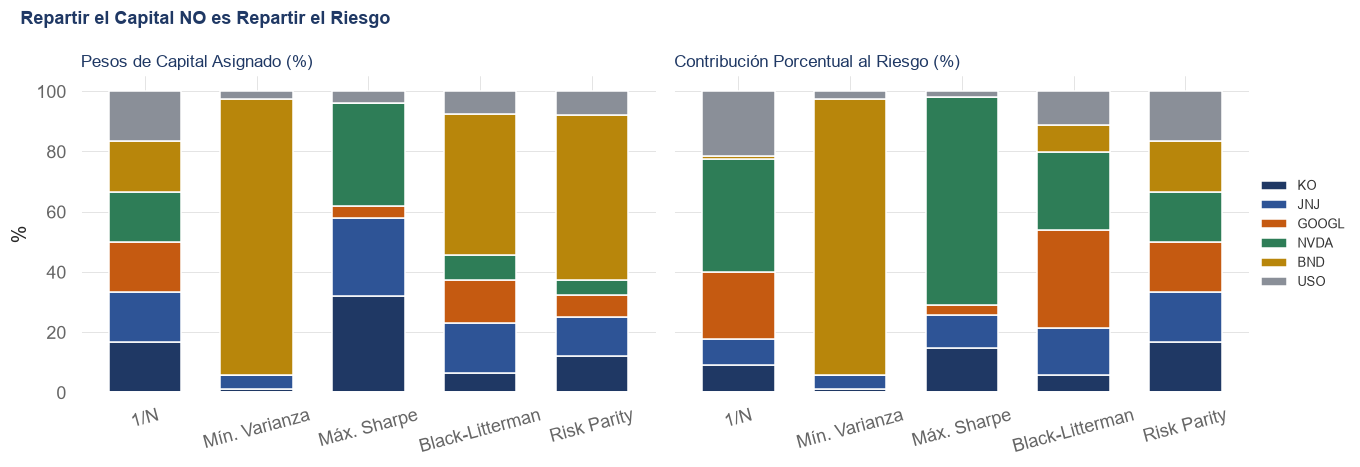

In [8]:
# Verificación: contribuciones con la fórmula, Risk Parity por minimización directa y pesos inversos a la volatilidad
def risk_contrib(w, S=cov):
    s = np.sqrt(w @ S @ w)
    mrc = (S @ w) / s   # Contribución marginal
    return w * mrc
# Optimización directa de Equal Risk Contribution (ERC) vía scipy
def risk_parity(S=cov):
    nn = S.shape[0]
    # Función objetivo: minimizar la suma cuadrática de desviaciones respecto al riesgo objetivo (sigma_p / n)
    obj = lambda w: np.sum((risk_contrib(w, S) - np.sqrt(w @ S @ w) / nn) ** 2) * 1e4
    res = sco.minimize(obj, np.ones(nn) / nn, bounds=[(1e-6, 1)] * nn,
                        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
                        options={"ftol": 1e-14, "maxiter": 1000})
    return res.x

w_rp = risk_parity()

# Optimización con Riskfolio-Lib
port = rp.Portfolio(returns=retornos)
port.assets_stats(method_mu="hist", method_cov="hist")

w_rp_rf = port.rp_optimization(model="Classic", rm="MV", rf=0, hist=True)
if w_rp_rf is None:
    w_rp_rf = pd.DataFrame(w_rp, index=cov_mat.index, columns=["weights"])

# Comparación con Heurística de Inverso de Volatilidad (1 / sigma)
w_iv = (1.0 / vol) / np.sum(1.0 / vol)

# Verificación matemática rigurosa
rc = risk_contrib(w_rp, cov)
vol_rp = np.sqrt(w_rp @ cov @ w_rp)
pct_rc = rc / rc.sum()

tab_rp = pd.DataFrame({
    "Volatilidad": vol,
    "w Inverso Vol (1/σ)": w_iv,
    "w Risk Parity (scipy)": w_rp,
    "w Risk Parity (Riskfolio)": w_rp_rf["weights"].values,
    "Contribución Riesgo (RC)": rc,
    "% del Riesgo Total": pct_rc
}, index=ASSETS)

display(tab_rp.style.format({
    "Volatilidad": "{:.2%}",
    "w Inverso Vol (1/σ)": "{:.2%}",
    "w Risk Parity (scipy)": "{:.2%}",
    "w Risk Parity (Riskfolio)": "{:.2%}",
    "Contribución Riesgo (RC)": "{:.2%}",
    "% del Riesgo Total": "{:.2%}"
}))

print(f"--- Verificación Matemática de Risk Parity ---")
print(f"Suma de Contribuciones al Riesgo (sum RC_i) : {rc.sum():.6%}")
print(f"Volatilidad Total del Portafolio (sigma_p)   : {vol_rp:.6%}")
print(f"Diferencia absoluta (|sum RC - sigma_p|)     : {abs(rc.sum() - vol_rp):.2e}")
print(f"Porcentaje de riesgo objetivo por activo     : {100 / n:.2f}%")
print(f"Discrepancia máxima en % de riesgo individual: {np.abs(pct_rc - 1/n).max():.2e}")

# Comparación Gráfica: Repartir el Capital vs Repartir el Riesgo
PORT2 = {
    "1/N": w_eq,
    "Mín. Varianza": w_mv,
    "Máx. Sharpe": w_ms,
    "Black-Litterman": w_bl_rf["weights"].values,
    "Risk Parity": w_rp
}

pesos_df = pd.DataFrame(PORT2, index=ASSETS).T
riesgo_df = pd.DataFrame({
    k: risk_contrib(np.asarray(w), cov) / np.sqrt(np.asarray(w) @ cov @ np.asarray(w))
    for k, w in PORT2.items()
}, index=ASSETS).T

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
(pesos_df * 100).plot(kind="bar", stacked=True, color=COLS, ax=axes[0], legend=False, width=0.65)
(riesgo_df * 100).plot(kind="bar", stacked=True, color=COLS, ax=axes[1], width=0.65)

axes[0].set_title("Pesos de Capital Asignado (%)", loc="left", fontsize=11)
axes[1].set_title("Contribución Porcentual al Riesgo (%)", loc="left", fontsize=11)
axes[1].legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1, 0.5))

for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.set_ylabel("%")

fig.suptitle("Repartir el Capital NO es Repartir el Riesgo", x=0.02, ha="left", fontsize=12, weight="bold", color=NAVY)
plt.tight_layout()
plt.show()

El inverso de la volatilidad asume que los activos no tienen covarianza entre sí, o sea, el riesgo se reparte de manera desigual. En cambio, en Risk Parity el ERC cruza las correlaciones y garantiza que el portafolio divida de manera equitativa el riesgo.

Si observamos el portafolio 1/N, el dividir el capital de manera igual no asegura dividir de manera equitativa el riesgo, ya que cada activo pondera de manera distinta al riesgo. Por lo tanto, si ocupamos esa estrategia un shock en el sector tecnológico destruirá al portafolio ya que NVDA y GOOGL tienen casi el 60% de la volatilidad. Si nos fijamos en Risk Parity, se logra una mejor diversificación en términos de volatilidad, todos los activos aportan la misma cantidad. Se está sobreponderando los activos de baja volatilidad (BND tiene el 54,82% del capital) y en cambio los activos de mayor volatilidad los limita.

## Evaluación de desempeño

Período Dentro de Muestra (In-Sample) : 2018-01-03 a 2023-01-04 (1260 días)
Período Fuera de Muestra (Out-of-Sample): 2023-01-05 a 2026-11-10 (966 días)
--- Pesos Calibrados Exclusivamente Dentro de Muestra ---


,KO,JNJ,GOOGL,NVDA,BND,USO
Markowitz (Máx. Sharpe),46.1%,14.0%,0.0%,39.9%,0.0%,0.0%
Black-Litterman,7.6%,18.3%,14.6%,7.7%,43.8%,8.0%
Risk Parity (ERC),11.0%,12.4%,7.1%,4.7%,57.7%,7.2%
Mínima Varianza,0.0%,6.2%,0.0%,0.0%,92.5%,1.3%
Equally Weighted (1/N),16.7%,16.7%,16.7%,16.7%,16.7%,16.7%
Benchmark Diversificado,15.0%,15.0%,15.0%,15.0%,30.0%,10.0%


--- Desempeño Comparativo Fuera de Muestra (2023 - 2026) ---


,N Efectivo,Sharpe Dentro,Retorno,CAGR,Volatilidad,Sharpe,Sortino,MDD,Duración DD (días),Calmar,TE,IR
Markowitz (Máx. Sharpe),2.6,0.71,39.32%,45.48%,19.06%,1.96,3.21,-14.46%,79,3.14,11.72%,1.21
Black-Litterman,3.8,0.47,18.76%,20.22%,8.22%,2.04,3.19,-8.20%,98,2.47,3.77%,-1.68
Risk Parity (ERC),2.7,0.38,13.63%,14.38%,6.12%,1.90,2.96,-6.03%,102,2.38,6.31%,-1.82
Mínima Varianza,1.2,-0.16,4.39%,4.34%,5.32%,0.45,0.65,-6.79%,209,0.64,10.57%,-1.96
Equally Weighted (1/N),6.0,0.53,28.84%,32.40%,12.39%,2.17,3.45,-13.25%,74,2.44,2.82%,1.33
Benchmark Diversificado,5.3,0.55,25.09%,27.78%,10.64%,2.17,3.47,-11.00%,75,2.53,0.00%,—


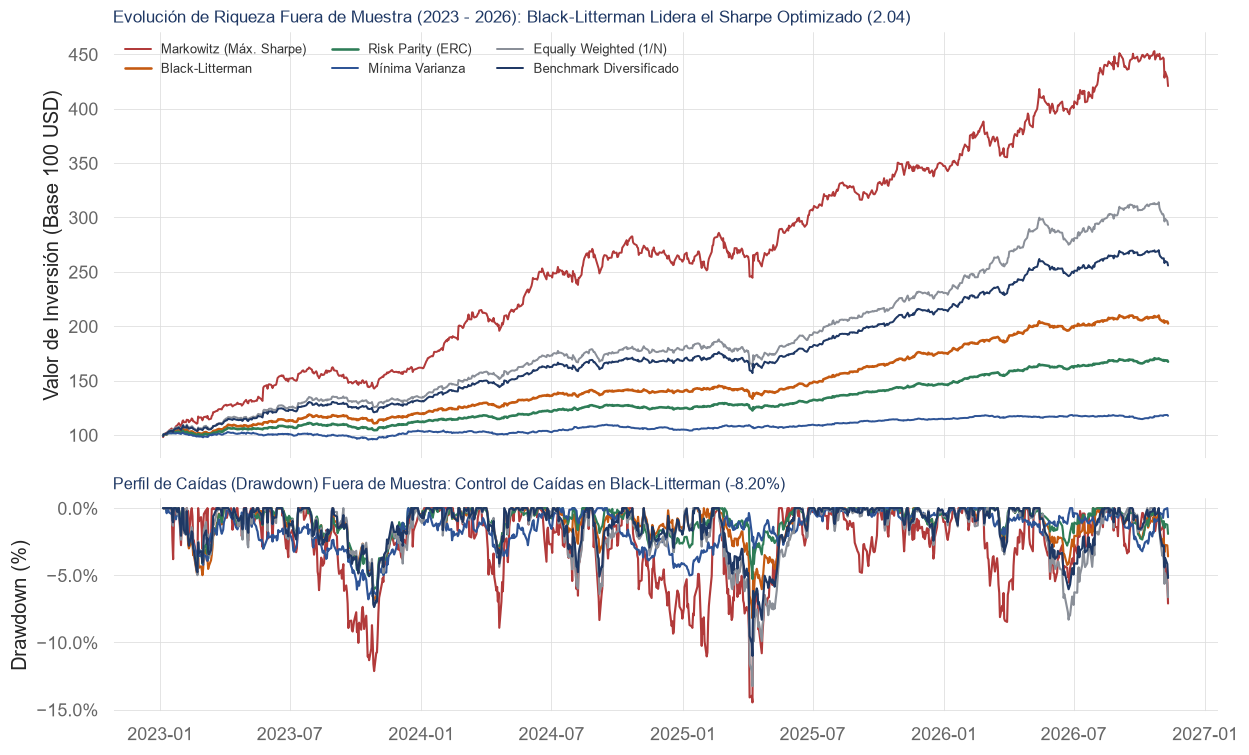

Resumen de QuantStats para Black-Litterman vs. Benchmark (Fuera de Muestra):

Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  2.0%
Periods/Year    252
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2023-01-05   2023-01-05
End Period           2026-11-10   2026-11-10
Risk-Free Rate       2.0%         2.0%
Time in Market       100.0%       100.0%

Cumulative Return    155.92%      102.58%
CAGR﹪               27.78%       20.22%

Sharpe               2.17         2.04
Prob. Sharpe Ratio   100.0%       100.0%
Sortino              3.47         3.19
Sortino/√2           2.45         2.26
Omega                1.45         1.41

Max Drawdown         -11.0%       -8.2%
Max DD Date          2025-04-08   2025-04-08
Max DD Period Start  2025-02-21   2025-02-21
Max DD Period End    2025-06-05   2025-06-06
Longest DD Days      107          138

Gain/Pain R

In [9]:
w_bm = np.array([BENCHMARK[a] for a in ASSETS])
# 1. Función de Métricas Financieras Rigurosas
def metricas(rp_, rb=None):
    """Calcula Retorno, CAGR, Volatilidad, Sharpe, Sortino, MDD, Duración DD, Calmar, TE e IR."""
    rp_ = np.asarray(rp_)
    wealth = np.cumprod(1 + rp_)
    n_days = len(rp_)
    cagr = wealth[-1] ** (ANN / n_days) - 1
    m, s = rp_.mean() * ANN, rp_.std(ddof=1) * np.sqrt(ANN)
    
    # Desviación a la baja para Sortino (respecto a rf diaria)
    downside_diff = np.minimum(rp_ - rfd, 0)
    dd_dev = np.sqrt(np.mean(downside_diff ** 2)) * np.sqrt(ANN)
    sortino = (m - RF) / dd_dev if dd_dev > 1e-12 else np.nan
    
    # Drawdown
    peak = np.maximum.accumulate(wealth)
    dd = wealth / peak - 1
    mdd = dd.min()
    
    # Duración de drawdown (días consecutivos bajo máximo previo)
    dur = run = 0
    for bajo in (dd < 0):
        run = run + 1 if bajo else 0
        dur = max(dur, run)
        
    calmar = cagr / abs(mdd) if abs(mdd) > 1e-12 else np.nan
    
    out = {
        "Retorno": m,
        "CAGR": cagr,
        "Volatilidad": s,
        "Sharpe": (m - RF) / s if s > 1e-12 else np.nan,
        "Sortino": sortino,
        "MDD": mdd,
        "Duración DD (días)": dur,
        "Calmar": calmar
    }
    
    if rb is not None:
        act = rp_ - np.asarray(rb)
        te = act.std(ddof=1) * np.sqrt(ANN)
        ir = (act.mean() * ANN) / te if te > 1e-12 else np.nan
        out["TE"], out["IR"] = te, ir
        
    return out

# 2. Partición Temporal Estricta:
# - In-Sample (Entrenamiento): 5 años exactos (2018-01-03 a 2023-01-04, 1260 ruedas bursátiles)
# - Out-of-Sample (Evaluación): Resto de la muestra (~4 años: 2023-01-05 a 2026-11-10, 966 ruedas bursátiles)
corte = 5 * ANN
ret_tr = retornos.iloc[:corte]
ret_te = retornos.iloc[corte:]
Rtr = ret_tr.values
Rte = ret_te.values

print(f"Período Dentro de Muestra (In-Sample) : {ret_tr.index[0]:%Y-%m-%d} a {ret_tr.index[-1]:%Y-%m-%d} ({len(ret_tr)} días)")
print(f"Período Fuera de Muestra (Out-of-Sample): {ret_te.index[0]:%Y-%m-%d} a {ret_te.index[-1]:%Y-%m-%d} ({len(ret_te)} días)")

# 3. Optimización con Información EXCLUSIVA de Dentro de Muestra
mu_tr = ret_tr.mean().values * ANN
cov_tr = ret_tr.cov().values * ANN

# Markowitz Max Sharpe in-sample
w_mkw_tr = max_sharpe_opt(mu_tr, cov_tr)

# Risk Parity in-sample
w_rp_tr = risk_parity(cov_tr)

# Black-Litterman in-sample
_, mu_bl_tr = black_litterman(cov_tr, w_mkt.values, P, Q)
w_bl_tr = max_sharpe_opt(mu_bl_tr, cov_tr)

# Mínima Varianza in-sample
res_mv_tr = sco.minimize(get_portf_vol, w0, args=(mu_tr, cov_tr), bounds=longterm, constraints=capital100)
w_mv_tr = res_mv_tr.x

# Portafolios a evaluar
cand = {
    "Markowitz (Máx. Sharpe)": w_mkw_tr,
    "Black-Litterman": w_bl_tr,
    "Risk Parity (ERC)": w_rp_tr,
    "Mínima Varianza": w_mv_tr,
    "Equally Weighted (1/N)": w_eq,
    "Benchmark Diversificado": w_bm
}

# 4. Tabla de Pesos y Métricas Comparativas
pesos_eval = pd.DataFrame(cand, index=ASSETS).T

# Evaluación Out-of-Sample (Benchmark es w_bm)
ret_bm_te = Rte @ w_bm
fuera = pd.DataFrame({k: metricas(Rte @ w, ret_bm_te) for k, w in cand.items()}).T

# Métricas complementarias
fuera.insert(0, "Sharpe Dentro", [metricas(Rtr @ w)["Sharpe"] for w in cand.values()])
fuera.insert(0, "N Efectivo", [1 / np.sum(np.asarray(w) ** 2) for w in cand.values()])

FMT = {
    "N Efectivo": "{:.1f}",
    "Sharpe Dentro": "{:.2f}",
    "Retorno": "{:.2%}",
    "CAGR": "{:.2%}",
    "Volatilidad": "{:.2%}",
    "Sharpe": "{:.2f}",
    "Sortino": "{:.2f}",
    "TE": "{:.2%}",
    "IR": "{:.2f}",
    "MDD": "{:.2%}",
    "Duración DD (días)": "{:.0f}",
    "Calmar": "{:.2f}"
}

print("--- Pesos Calibrados Exclusivamente Dentro de Muestra ---")
display(pesos_eval.style.format("{:.1%}"))

print("--- Desempeño Comparativo Fuera de Muestra (2023 - 2026) ---")
display(fuera.style.format(FMT, na_rep="—"))

# 5. Evolución de la Riqueza (Base US$100) y Curvas de Drawdown Fuera de Muestra
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7.0), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

colores_port = [RED, ACCENT, GREEN, BLUE, GREY, NAVY]
for (nombre, w), col in zip(cand.items(), colores_port):
    r_serie = pd.Series(Rte @ w, index=ret_te.index)
    wealth_serie = 100 * np.cumprod(1 + r_serie)
    dd_serie = wealth_serie / np.maximum.accumulate(wealth_serie) - 1
    
    axes[0].plot(wealth_serie.index, wealth_serie, label=nombre, color=col, lw=1.7 if "Risk Parity" in nombre or "Black" in nombre else 1.3)
    axes[1].plot(dd_serie.index, dd_serie, label=nombre, color=col, lw=1.4)

axes[0].set_ylabel("Valor de Inversión (Base 100 USD)")
axes[0].set_title("Evolución de Riqueza Fuera de Muestra (2023 - 2026): Black-Litterman Lidera el Sharpe Optimizado (2.04)", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8.5, ncol=3, loc="upper left")

axes[1].set_ylabel("Drawdown (%)")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Perfil de Caídas (Drawdown) Fuera de Muestra: Control de Caídas en Black-Litterman (-8.20%)", loc="left", fontsize=10.5)

plt.tight_layout()
plt.show()

# 6. Reporte básico con QuantStats comparando Black-Litterman vs Benchmark
print("Resumen de QuantStats para Black-Litterman vs. Benchmark (Fuera de Muestra):")
qs.reports.metrics(pd.Series(Rte @ w_bl_tr, index=ret_te.index, name="Black-Litterman"),
                   benchmark=pd.Series(ret_bm_te, index=ret_te.index, name="Benchmark"),
                   rf=RF, mode="basic")

Al observar los resultados fuera de muestra, el portafolio de Markowitz alcanza el retorno anualizado más alto de todos (39,32%), pero a costa del perfil más riesgoso y el mayor Drawdown del período (-14,46%). Este elevado rendimiento no se debe a una diversificación óptima, sino a una alta concentración de capital en los activos más volátiles.

Por su parte, Black-Litterman logra el mejor desempeño ajustado por riesgo entre los modelos optimizados, con un ratio de Sharpe de 2,04, superando a Markowitz (1,96) y a Risk Parity (1,90), a la vez que mantiene pérdidas significativamente más acotadas con un Drawdown de solo -8,20%.

En cuanto a Risk Parity, la estrategia se consolida como la más defensiva y resiliente del análisis: registra la menor volatilidad anualizada (6,12%) y la caída máxima más baja de todas las alternativas (-6,03%).

En relación con el Benchmark, tanto Black-Litterman como Risk Parity evidencian una gestión del riesgo sustancialmente superior, logrando una menor volatilidad y protegiendo mejor el capital ante caídas severas (frente al -11,00% de Drawdown del mercado de referencia). Sin embargo, ambos modelos registraron retornos y ratios de Sharpe ligeramente inferiores a los de la referencia pasiva.

## Bootstrap de pesos y análisis de rotación.

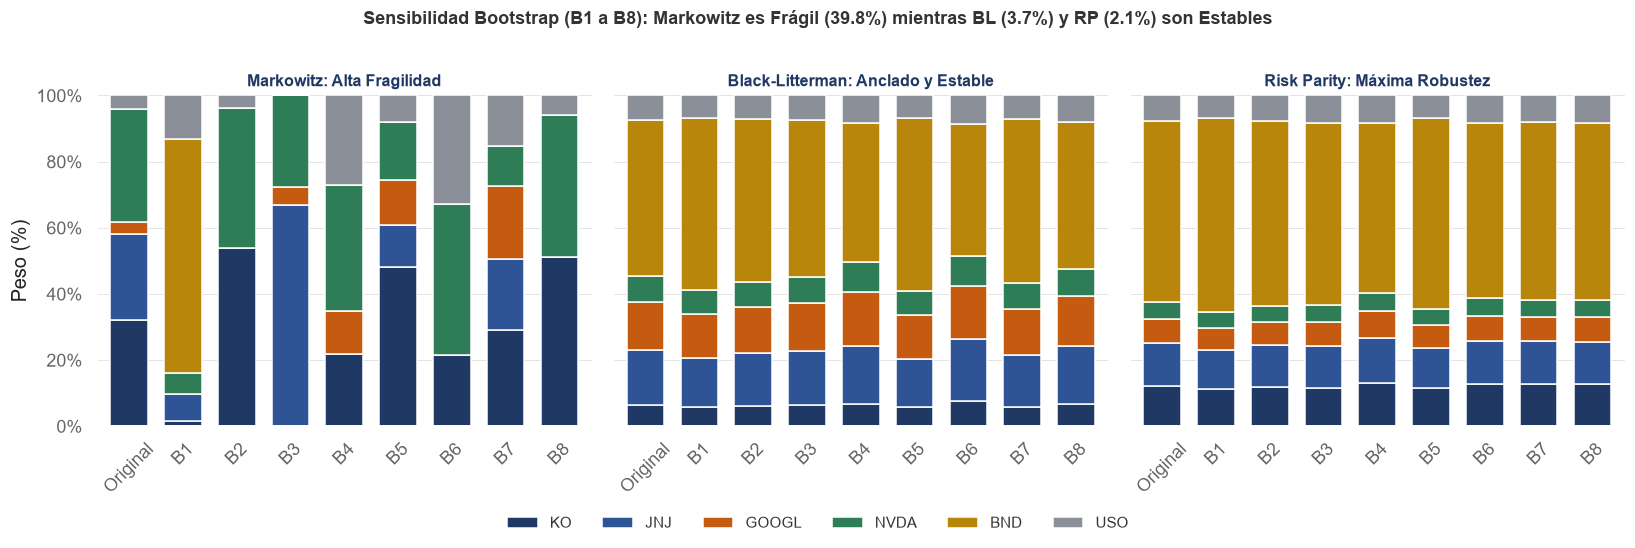

--- Rango de Pesos entre Remuestreos (Máx - Mín) ---


,Rango Markowitz,Rango Black-Litterman,Rango Risk Parity
KO,54.0%,1.8%,2.0%
JNJ,67.0%,4.1%,1.6%
GOOGL,22.0%,3.2%,1.5%
NVDA,39.2%,1.9%,0.7%
BND,70.6%,12.1%,7.2%
USO,32.8%,1.7%,1.7%



--- Rotación Promedio (Turnover) ante Remuestreo ---
Markowitz       : 39.8%
Black-Litterman : 3.7%
Risk Parity     : 2.1%


In [10]:
# --- Fragilidad y Estabilidad Comparativa (Estilo Profesor con Leyenda Horizontal Abajo) ---
rng_b = np.random.default_rng(42)

rem_ms = {"Original": w_ms}
rem_bl = {"Original": w_bl}
rem_rp = {"Original": w_rp}

for k in range(1, 9):
  idx = rng_b.integers(0, len(R), len(R))
  Rb = R[idx]
  mu_b = Rb.mean(0) * ANN
  cov_b = np.cov(Rb.T) * ANN

  # 1. Markowitz
  rem_ms[f"B{k}"] = max_sharpe_opt(mu_b, cov_b)

  # 2. Black-Litterman
  _, mu_bl_b = black_litterman(cov_b, w_mkt.values, P, Q)
  rem_bl[f"B{k}"] = max_sharpe_opt(mu_bl_b, cov_b)

  # 3. Risk Parity
  rem_rp[f"B{k}"] = risk_parity(cov_b)

tab_ms = pd.DataFrame(rem_ms, index=ASSETS)
tab_bl = pd.DataFrame(rem_bl, index=ASSETS)
tab_rp = pd.DataFrame(rem_rp, index=ASSETS)

# Gráfico comparativo de barras apiladas (3 paneles)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

titulos = [
    "Markowitz: Alta Fragilidad",
    "Black-Litterman: Anclado y Estable",
    "Risk Parity: Máxima Robustez",
]
tablas = [tab_ms, tab_bl, tab_rp]

for ax, tab, titulo in zip(axes, tablas, titulos):
  (tab.T * 100).plot(
      kind="bar", stacked=True, color=COLS, ax=ax, width=0.7, legend=False
  )
  ax.set_title(titulo, fontweight="bold", fontsize=10.5)
  ax.set_ylabel("Peso (%)")
  ax.yaxis.set_major_formatter(PercentFormatter(100))
  ax.tick_params(axis="x", rotation=45)

# --- Leyenda Horizontal Abajo ---
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=len(ASSETS),
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(0.5, -0.06),
)

plt.suptitle(
    "Sensibilidad Bootstrap (B1 a B8): Markowitz es Frágil (39.8%) mientras BL (3.7%) y RP (2.1%) son Estables",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

# Comparación de Rangos (Máx - Mín)
comp_rango = pd.DataFrame(
    {
        "Rango Markowitz": tab_ms.max(axis=1) - tab_ms.min(axis=1),
        "Rango Black-Litterman": tab_bl.max(axis=1) - tab_bl.min(axis=1),
        "Rango Risk Parity": tab_rp.max(axis=1) - tab_rp.min(axis=1),
    },
    index=ASSETS,
)

print("--- Rango de Pesos entre Remuestreos (Máx - Mín) ---")
display(comp_rango.style.format("{:.1%}"))

# Rotación Promedio (Turnover)
to_ms = np.mean(
    [0.5 * np.sum(np.abs(tab_ms[f"B{k}"].values - w_ms)) for k in range(1, 9)]
)
to_bl = np.mean(
    [0.5 * np.sum(np.abs(tab_bl[f"B{k}"].values - w_bl)) for k in range(1, 9)]
)
to_rp = np.mean(
    [0.5 * np.sum(np.abs(tab_rp[f"B{k}"].values - w_rp)) for k in range(1, 9)]
)

print("\n--- Rotación Promedio (Turnover) ante Remuestreo ---")
print(f"Markowitz       : {to_ms:.1%}")
print(f"Black-Litterman : {to_bl:.1%}")
print(f"Risk Parity     : {to_rp:.1%}")

Observando el análisis de sensibilidad, se evidencia la fragilidad estructural del modelo de Markowitz frente a la robustez de Black-Litterman y Risk Parity:

- Markowitz presenta la rotación promedio más alta, con un 39,8% y una dispersión de hasta 70,6% (en BND). Esta elevada inestabilidad generaría altos costos de transacción y corretaje en la práctica.

- Black-Litterman amortigua el ruido muestral: su rotación promedio cae a un 3,7% y la máxima dispersión observada fue de 12,1% (en BND), ofreciendo una asignación de capital mucho más equilibrada y consistente.

- Risk Parity presenta la mayor estabilidad entre los tres modelos, con una rotación promedio de apenas 2,1% y una fluctuación máxima de 7,2% (en BND). Su principal ventaja es que no depende de retornos esperados, basándose únicamente en la matriz de covarianza, lo que lo convierte en el portafolio más seguro y predecible.

En conclusión, el portafolio de Markowitz resulta inviable para un mandato institucional, mientras que Risk Parity y Black-Litterman proporcionan soluciones robustas que minimizan tanto el riesgo de estimación como los costos de rebalanceo.

## Recomendación
En base al trabajo realizado, se recomienda implementar el portafolio **Black-Litterman** (`BND` 43,8%, `JNJ` 18,3%, `GOOGL` 14,6%, `USO` 8,0%, `NVDA` 7,7%, `KO` 7,6%), dado que lidera el desempeño ajustado por riesgo fuera de muestra entre los modelos optimizados con un **ratio de Sharpe de 2,04** y **Sortino de 3,19**, un retorno anualizado de **18,76%**, volatilidad controlada (**8,22%**), un **Drawdown máximo acotado a -8,20%** (inferior al -11,00% del Benchmark) y una baja rotación ante remuestreos (**3,7%**). Se descarta **Markowitz** pese a su mayor retorno nominal por su extrema concentración en pocos activos y alta inestabilidad paramétrica (rotación de 39,8%), y se descarta **Risk Parity** por sacrificar excesiva rentabilidad (13,63%) y eficiencia (Sharpe 1,90) al sobreponderar renta fija.

In [11]:
# ==============================================================================
# DESCARGA Y EXPORTACIÓN DE TODOS LOS GRÁFICOS DEL TALLER
# ==============================================================================
import os
import zipfile
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.ticker import PercentFormatter
from scipy import stats

# Carpeta de salida para almacenar las imágenes
CARPETA_GRAFICOS = "graficos_taller4"
os.makedirs(CARPETA_GRAFICOS, exist_ok=True)
print(f"Guardando gráficos en '{CARPETA_GRAFICOS}/'...")

# ------------------------------------------------------------------------------
# 1. Matriz de Correlación
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(ASSETS)
ax.set_yticks(range(n))
ax.set_yticklabels(ASSETS)
for i in range(n):
    for j in range(n):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(val) > 0.45 else "black", weight="bold" if abs(val) > 0.5 else "normal")
ax.set_title("Matriz de Correlación: Desacoplamiento entre Acciones, Bonos y Commodities", loc="left", fontsize=11)
fig.colorbar(im, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "01_matriz_correlacion.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 2. Análisis de Normalidad (Histograma Logarítmico y Gráfico Q-Q)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(z, bins=60, density=True, color=NAVY, alpha=0.55, label="Portafolio 1/N")
axes[0].plot(xs, stats.norm.pdf(xs), color=ACCENT, lw=1.6, label="Normal")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-4, 1)
axes[0].legend(frameon=False)
axes[0].set_title("Histograma (escala log): colas sobre la normal", loc="left", fontsize=10)
stats.probplot(z, dist="norm", plot=axes[1])
axes[1].set_title("")  # Elimina el título por defecto "Probability Plot"
axes[1].set_title("Q-Q: los extremos se separan de la recta", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "02_normalidad_retornos.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 3. Frontera Eficiente de Markowitz y LMC
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.2, 5.5))
sc = ax.scatter(rand_v, rand_r, c=rand_s, cmap="Spectral_r", s=6, alpha=0.45, label="Carteras Simuladas (10k)")
ax.plot(vols_range[~ef_mask], rtns_range[~ef_mask], color=GREY, ls="--", lw=1.5, label="Tramo Ineficiente")
ax.plot(vols_range[ef_mask], rtns_range[ef_mask], color=NAVY, lw=2.8, label="Frontera Eficiente (Long-Only)")
ax.plot(xs_lmc, lmc, color=ACCENT, ls="--", lw=1.8, label=f"LMC (Tangente Sharpe={s_ms:.2f})")
ax.scatter(vol, mu, color=GREY, marker="D", s=45, zorder=5, label="Activos Individuales")
for i, a in enumerate(ASSETS):
    ax.annotate(f" {a}", (vol[i], mu[i]), xytext=(4, 2), textcoords="offset points", fontsize=8.5, weight="bold")
ax.scatter(v_mv, r_mv, marker="*", s=220, color=BLUE, zorder=6, label=f"Mínima Varianza (σ={v_mv:.1%}, μ={r_mv:.1%})")
ax.scatter(v_ms, r_ms, marker="*", s=260, color=GOLDC, zorder=6, label=f"Máximo Sharpe (σ={v_ms:.1%}, μ={r_ms:.1%})")
ax.scatter(0, RF, marker="o", s=80, color=ACCENT, zorder=6, label=f"Tasa Libre de Riesgo rf ({RF:.1%})")
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Volatilidad Anualizada ($\\sigma$)")
ax.set_ylabel("Retorno Esperado Anualizado ($\\mu$)")
ax.set_title("Frontera de Markowitz desde (0, 0): Máximo Sharpe (1.15) Concentra el Capital e Ignora los Bonos", loc="left", fontsize=11)
cb = fig.colorbar(sc, label="Ratio de Sharpe")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "03_frontera_eficiente_markowitz.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 4. Retornos y Pesos Black-Litterman vs Histórico y Mercado
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
pd.DataFrame({"Histórico": mu, "Equilibrio (Π + rf)": Pi_rf, "Black-Litterman": mu_bl}, index=ASSETS)\
    .plot(kind="bar", color=[GREY, NAVY, ACCENT], ax=axes[0], rot=0, width=0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Retornos: Black-Litterman Ancla el Histórico al Equilibrio", loc="left", fontsize=10.5)
axes[0].legend(frameon=False, fontsize=8.5)

pd.DataFrame({"Mercado (w_mkt)": w_mkt.values, "Markowitz (MVO)": w_ms, "Black-Litterman": w_bl_rf["weights"].values}, index=ASSETS)\
    .plot(kind="bar", color=[NAVY, GREY, ACCENT], ax=axes[1], rot=0, width=0.75)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Pesos: BL Evita la Concentración Extrema de Markowitz", loc="left", fontsize=10.5)
axes[1].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "04_bl_retornos_pesos.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 5. Sensibilidad a la Confianza en Black-Litterman
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sens_df.plot(marker="o", cmap="tab10", logx=True, ax=ax)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Nivel de Confianza en las Visiones (Escala Log)")
ax.set_ylabel("Peso en Portafolio BL")
ax.set_title("Sensibilidad a la Confianza: A mayor convicción, mayor inclinación hacia las visiones", loc="left", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "05_bl_sensibilidad_confianza.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 6. Asignación de Capital Black-Litterman (Gráfico Circular / Pie)
# ------------------------------------------------------------------------------
ax_pie = rp.plot_pie(w=w_bl_rf, title="Asignación Black-Litterman: Diversificación en los 6 Activos con Ancla en Bonos (47%)", others=0.01, nrow=25, cmap="tab20",
                     height=5, width=9, ax=None)
fig_pie = ax_pie.get_figure()
fig_pie.tight_layout()
fig_pie.savefig(os.path.join(CARPETA_GRAFICOS, "06_bl_pie_asignacion.png"), dpi=300, bbox_inches="tight")
plt.close(fig_pie)

# ------------------------------------------------------------------------------
# 7. Repartir el Capital NO es Repartir el Riesgo (Pesos vs Contribución al Riesgo)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
(pesos_df * 100).plot(kind="bar", stacked=True, color=COLS, ax=axes[0], legend=False, width=0.65)
(riesgo_df * 100).plot(kind="bar", stacked=True, color=COLS, ax=axes[1], width=0.65)
axes[0].set_title("Pesos de Capital Asignado (%)", loc="left", fontsize=11)
axes[1].set_title("Contribución Porcentual al Riesgo (%)", loc="left", fontsize=11)
axes[1].legend(frameon=False, fontsize=8.5, loc="center left", bbox_to_anchor=(1, 0.5))
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    ax.set_ylabel("%")
fig.suptitle("Repartir el Capital NO es Repartir el Riesgo", x=0.02, ha="left", fontsize=12, weight="bold", color=NAVY)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "07_capital_vs_riesgo.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 8. Evolución de Riqueza y Drawdown Fuera de Muestra
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(11.5, 7.0), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for (nombre, w), col in zip(cand.items(), colores_port):
    r_serie = pd.Series(Rte @ w, index=ret_te.index)
    wealth_serie = 100 * np.cumprod(1 + r_serie)
    dd_serie = wealth_serie / np.maximum.accumulate(wealth_serie) - 1
    axes[0].plot(wealth_serie.index, wealth_serie, label=nombre, color=col, lw=1.7 if "Risk Parity" in nombre or "Black" in nombre else 1.3)
    axes[1].plot(dd_serie.index, dd_serie, label=nombre, color=col, lw=1.4)
axes[0].set_ylabel("Valor de Inversión (Base 100 USD)")
axes[0].set_title("Evolución de Riqueza Fuera de Muestra (2023 - 2026): Black-Litterman Lidera el Sharpe Optimizado (2.04)", loc="left", fontsize=11)
axes[0].legend(frameon=False, fontsize=8.5, ncol=3, loc="upper left")
axes[1].set_ylabel("Drawdown (%)")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("Perfil de Caídas (Drawdown) Fuera de Muestra: Control de Caídas en Black-Litterman (-8.20%)", loc="left", fontsize=10.5)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "08_evolucion_riqueza_drawdown.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# 9. Sensibilidad ante Remuestreos Bootstrap (B1 a B8)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
titulos_boot = [
    "Markowitz: Alta Fragilidad",
    "Black-Litterman: Anclado y Estable",
    "Risk Parity: Máxima Robustez",
]
tablas_boot = [tab_ms, tab_bl, tab_rp]
for ax, tab, titulo in zip(axes, tablas_boot, titulos_boot):
    (tab.T * 100).plot(kind="bar", stacked=True, color=COLS, ax=ax, width=0.7, legend=False)
    ax.set_title(titulo, fontweight="bold", fontsize=10.5)
    ax.set_ylabel("Peso (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.tick_params(axis="x", rotation=45)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(ASSETS), frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Sensibilidad Bootstrap (B1 a B8): Markowitz es Frágil (39.8%) mientras BL (3.7%) y RP (2.1%) son Estables", fontsize=12, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_GRAFICOS, "09_bootstrap_sensibilidad_pesos.png"), dpi=300, bbox_inches="tight")
plt.close(fig)

# ------------------------------------------------------------------------------
# Creación de Archivo Comprimido .zip con todos los gráficos
# ------------------------------------------------------------------------------
ZIP_FILENAME = "graficos_taller4.zip"
with zipfile.ZipFile(ZIP_FILENAME, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, _, archivos in os.walk(CARPETA_GRAFICOS):
        for archivo in sorted(archivos):
            if archivo.endswith(".png"):
                ruta_completa = os.path.join(root, archivo)
                zipf.write(ruta_completa, arcname=archivo)

archivos_guardados = sorted([f for f in os.listdir(CARPETA_GRAFICOS) if f.endswith(".png")])
print(f"\n========================================================")
print(f"✓ {len(archivos_guardados)} gráficos guardados exitosamente en '{CARPETA_GRAFICOS}/':")
for arch in archivos_guardados:
    tam_kb = os.path.getsize(os.path.join(CARPETA_GRAFICOS, arch)) / 1024
    print(f"   • {arch} ({tam_kb:.1f} KB)")
print(f"✓ Paquete comprimido creado: '{ZIP_FILENAME}' ({os.path.getsize(ZIP_FILENAME)/1024:.1f} KB)")
print(f"========================================================")

# ------------------------------------------------------------------------------
# Descarga automática en el navegador (Google Colab) o aviso para entorno local
# ------------------------------------------------------------------------------
try:
    from google.colab import files
    print("\n[Google Colab] Iniciando la descarga automática del archivo comprimido...")
    files.download(ZIP_FILENAME)
    print("✓ Descarga completada.")
except (ImportError, Exception):
    print("\n[Entorno Local / Jupyter / VS Code]")
    print(f"Los gráficos ya están disponibles en:")
    print(f" 1. Carpeta local: {os.path.abspath(CARPETA_GRAFICOS)}")
    print(f" 2. Archivo ZIP  : {os.path.abspath(ZIP_FILENAME)}")



Guardando gráficos en 'graficos_taller4/'...

✓ 9 gráficos guardados exitosamente en 'graficos_taller4/':
   • 01_matriz_correlacion.png (151.7 KB)
   • 02_normalidad_retornos.png (162.1 KB)
   • 03_frontera_eficiente_markowitz.png (488.1 KB)
   • 04_bl_retornos_pesos.png (141.4 KB)
   • 05_bl_sensibilidad_confianza.png (145.5 KB)
   • 06_bl_pie_asignacion.png (194.6 KB)
   • 07_capital_vs_riesgo.png (156.9 KB)
   • 08_evolucion_riqueza_drawdown.png (774.5 KB)
   • 09_bootstrap_sensibilidad_pesos.png (169.7 KB)
✓ Paquete comprimido creado: 'graficos_taller4.zip' (2205.4 KB)

[Entorno Local / Jupyter / VS Code]
Los gráficos ya están disponibles en:
 1. Carpeta local: c:\Users\20fac\PycharmProjects\Business_Analytics\Finanzas_Computacionales\Laboratorio 4\graficos_taller4
 2. Archivo ZIP  : c:\Users\20fac\PycharmProjects\Business_Analytics\Finanzas_Computacionales\Laboratorio 4\graficos_taller4.zip
